## Phase 1

In [1]:
!pip install -q kagglehub

In [2]:
import kagglehub

path = kagglehub.dataset_download(
    "tawsifurrahman/covid19-radiography-database"
)

print("Path to dataset files:", path)

100%|██████████| 778M/778M [00:05<00:00, 159MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5


In [3]:
import os

print("Dataset location:", path)
print("\nContents:")

for item in os.listdir(path):
    item_path = os.path.join(path, item)

    if os.path.isdir(item_path):
        print(f"📁 {item}/")
    else:
        print(f"📄 {item}")

Dataset location: /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5

Contents:
📁 COVID-19_Radiography_Dataset/


In [4]:
from pathlib import Path

dataset_path = Path(path)

print("Searching for class directories...\n")

for folder in dataset_path.rglob("*"):
    if folder.is_dir() and folder.name in {
        "COVID",
        "Normal",
        "Lung_Opacity",
        "Viral Pneumonia"
    }:
        print(folder)

Searching for class directories...

/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Lung_Opacity
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Viral Pneumonia
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/COVID
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Normal


In [5]:
from collections import Counter

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

CLASS_NAMES = [
    "COVID",
    "Normal",
    "Lung_Opacity",
    "Viral Pneumonia"
]

counts = Counter()

for class_name in CLASS_NAMES:
    for folder in dataset_path.rglob(class_name):
        if not folder.is_dir():
            continue

        images_dir = folder / "images"
        search_dir = images_dir if images_dir.is_dir() else folder

        counts[class_name] += sum(
            1 for file in search_dir.rglob("*")
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )

print("Dataset summary:\n")

for class_name in CLASS_NAMES:
    print(f"{class_name:20s}: {counts[class_name]}")

print(f"\nTotal images: {sum(counts.values())}")

Dataset summary:

COVID               : 3616
Normal              : 10192
Lung_Opacity        : 6012
Viral Pneumonia     : 1345

Total images: 21165


In [6]:
from pathlib import Path

dataset_path = Path(path)

print("Dataset exists:", dataset_path.exists())
print("Dataset location:", dataset_path)
print("\nTop-level contents:")

for item in sorted(dataset_path.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)

Dataset exists: True
Dataset location: /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5

Top-level contents:
📁 COVID-19_Radiography_Dataset


In [7]:
from pathlib import Path

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

CLASS_NAMES = [
    "COVID",
    "Normal",
    "Lung_Opacity",
    "Viral Pneumonia"
]

class_image_dirs = {}

for class_name in CLASS_NAMES:
    matches = [
        folder
        for folder in dataset_path.rglob(class_name)
        if folder.is_dir()
    ]

    for folder in matches:
        images_dir = folder / "images"

        if images_dir.is_dir():
            class_image_dirs[class_name] = images_dir
            break

        # Use the class directory only if it contains images directly.
        if any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            for p in folder.iterdir()
        ):
            class_image_dirs[class_name] = folder
            break

print("Detected image directories:\n")

for class_name in CLASS_NAMES:
    if class_name in class_image_dirs:
        print(f"{class_name:20s} -> {class_image_dirs[class_name]}")
    else:
        print(f"{class_name:20s} -> NOT FOUND")

Detected image directories:

COVID                -> /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/COVID/images
Normal               -> /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Normal/images
Lung_Opacity         -> /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Lung_Opacity/images
Viral Pneumonia      -> /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Viral Pneumonia/images


In [8]:
from collections import Counter

image_counts = Counter()
image_paths_by_class = {}

for class_name, image_dir in class_image_dirs.items():
    image_paths = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    image_paths_by_class[class_name] = image_paths
    image_counts[class_name] = len(image_paths)

print("DATASET SUMMARY")
print("=" * 45)

for class_name in CLASS_NAMES:
    print(f"{class_name:20s}: {image_counts[class_name]:,}")

print("=" * 45)
print(f"Total images: {sum(image_counts.values()):,}")

DATASET SUMMARY
COVID               : 3,616
Normal              : 10,192
Lung_Opacity        : 6,012
Viral Pneumonia     : 1,345
Total images: 21,165


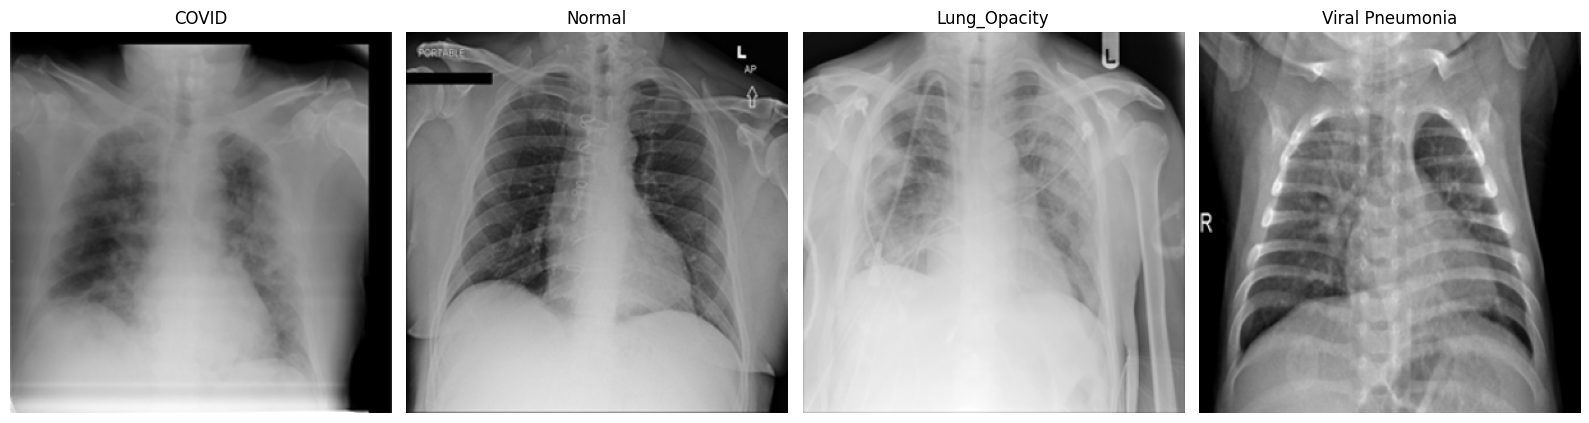

In [9]:
import cv2
import matplotlib.pyplot as plt
import random

available_classes = [
    class_name
    for class_name in CLASS_NAMES
    if image_paths_by_class.get(class_name)
]

fig, axes = plt.subplots(
    1,
    len(available_classes),
    figsize=(16, 5)
)

if len(available_classes) == 1:
    axes = [axes]

for ax, class_name in zip(axes, available_classes):
    sample_path = random.choice(image_paths_by_class[class_name])

    image = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)

    if image is not None:
        ax.imshow(image, cmap="gray")
        ax.set_title(class_name)
    else:
        ax.set_title(f"{class_name}\nRead error")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import cv2

invalid_images = []

for class_name, paths in image_paths_by_class.items():
    for image_path in paths:
        image = cv2.imread(str(image_path))

        if image is None:
            invalid_images.append((class_name, str(image_path)))

print("Unreadable images:", len(invalid_images))

for class_name, image_path in invalid_images[:10]:
    print(class_name, "->", image_path)

Unreadable images: 0


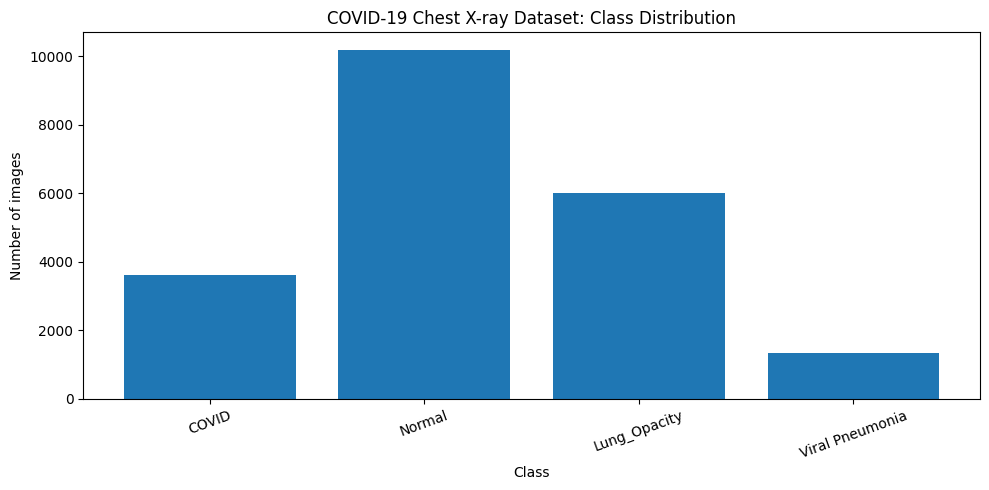

In [11]:
import matplotlib.pyplot as plt

labels = list(image_counts.keys())
values = [image_counts[label] for label in labels]

plt.figure(figsize=(10, 5))
plt.bar(labels, values)
plt.title("COVID-19 Chest X-ray Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Phase 2

In [12]:
from pathlib import Path

print("Sample filenames from each class:\n")

for class_name in CLASS_NAMES:
    paths = image_paths_by_class.get(class_name, [])

    print(f"\n{class_name}:")

    for image_path in paths[:5]:
        print(" ", image_path.name)

Sample filenames from each class:


COVID:
  COVID-1.png
  COVID-10.png
  COVID-100.png
  COVID-1000.png
  COVID-1001.png

Normal:
  Normal-1.png
  Normal-10.png
  Normal-100.png
  Normal-1000.png
  Normal-10000.png

Lung_Opacity:
  Lung_Opacity-1.png
  Lung_Opacity-10.png
  Lung_Opacity-100.png
  Lung_Opacity-1000.png
  Lung_Opacity-1001.png

Viral Pneumonia:
  Viral Pneumonia-1.png
  Viral Pneumonia-10.png
  Viral Pneumonia-100.png
  Viral Pneumonia-1000.png
  Viral Pneumonia-1001.png


In [13]:
metadata_extensions = {".csv", ".xlsx", ".xls", ".json", ".txt"}

metadata_files = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in metadata_extensions
]

print("Potential metadata files:\n")

if metadata_files:
    for file in metadata_files[:30]:
        print(file)
else:
    print("No metadata files found.")

Potential metadata files:

/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/COVID.metadata.xlsx
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/README.md.txt
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Normal.metadata.xlsx
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Lung_Opacity.metadata.xlsx
/root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/Viral Pneumonia.metadata.xlsx


In [14]:
import hashlib
from collections import defaultdict

def sha256_file(file_path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


hash_to_paths = defaultdict(list)

for class_name, paths in image_paths_by_class.items():
    for image_path in paths:
        file_hash = sha256_file(image_path)
        hash_to_paths[file_hash].append((class_name, image_path))

duplicate_groups = {
    file_hash: entries
    for file_hash, entries in hash_to_paths.items()
    if len(entries) > 1
}

print("Unique file hashes:", len(hash_to_paths))
print("Exact duplicate groups:", len(duplicate_groups))

for file_hash, entries in list(duplicate_groups.items())[:5]:
    print("\nDuplicate group:")

    for class_name, image_path in entries:
        print(f"  {class_name}: {image_path.name}")

Unique file hashes: 21111
Exact duplicate groups: 42

Duplicate group:
  COVID: COVID-137.png
  COVID: COVID-139.png

Duplicate group:
  COVID: COVID-18.png
  COVID: COVID-21.png

Duplicate group:
  COVID: COVID-2084.png
  COVID: COVID-2085.png

Duplicate group:
  COVID: COVID-2416.png
  COVID: COVID-2418.png

Duplicate group:
  COVID: COVID-2420.png
  COVID: COVID-2421.png


In [15]:
import pandas as pd

records = []
cross_class_duplicates = []

for file_hash, entries in hash_to_paths.items():
    labels = {class_name for class_name, _ in entries}

    if len(labels) > 1:
        cross_class_duplicates.append(entries)
        continue

    class_name, image_path = entries[0]

    records.append({
        "filepath": str(image_path),
        "label": class_name,
        "sha256": file_hash
    })

df = pd.DataFrame(records)

print("Original images:", sum(len(v) for v in image_paths_by_class.values()))
print("Unique images retained:", len(df))
print("Cross-class duplicate groups requiring review:",
      len(cross_class_duplicates))

print("\nClass counts after exact-deduplication:")
print(df["label"].value_counts())

Original images: 21165
Unique images retained: 21111
Cross-class duplicate groups requiring review: 0

Class counts after exact-deduplication:
label
Normal             10191
Lung_Opacity        6012
COVID               3570
Viral Pneumonia     1338
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

SEED = 42

# First: reserve 15% for testing.
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=SEED,
    stratify=df["label"]
)

# Second: reserve 15% of the original dataset for validation.
# 0.15 / 0.85 gives the required validation fraction
# of the remaining 85% of images.
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training images: 14777
Validation images: 3167
Testing images: 3167
Total: 21111


In [17]:
split_counts = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).fillna(0).astype(int)

split_counts = split_counts.reindex(CLASS_NAMES, fill_value=0)

print("Number of images per class in each split:\n")
display(split_counts)

print("\nPercentage distribution within each split:\n")

percentage_table = (
    split_counts.div(split_counts.sum(axis=0), axis=1) * 100
).round(2)

display(percentage_table)

Number of images per class in each split:



,Training,Validation,Testing
label,,,
COVID,2500,535,535
Normal,7133,1529,1529
Lung_Opacity,4208,902,902
Viral Pneumonia,936,201,201



Percentage distribution within each split:



,Training,Validation,Testing
label,,,
COVID,16.92,16.89,16.89
Normal,48.27,48.28,48.28
Lung_Opacity,28.48,28.48,28.48
Viral Pneumonia,6.33,6.35,6.35


In [18]:
from pathlib import Path

SPLIT_DIR = Path("/content/covid19_project/splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Split manifests saved to:", SPLIT_DIR)

for filename in ["train.csv", "validation.csv", "test.csv"]:
    file_path = SPLIT_DIR / filename
    print(f"{filename}: {file_path.stat().st_size / 1024:.2f} KB")

Split manifests saved to: /content/covid19_project/splits
train.csv: 3234.36 KB
validation.csv: 693.23 KB
test.csv: 693.19 KB


In [19]:
from google.colab import files

files.download(str(SPLIT_DIR / "train.csv"))
files.download(str(SPLIT_DIR / "validation.csv"))
files.download(str(SPLIT_DIR / "test.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

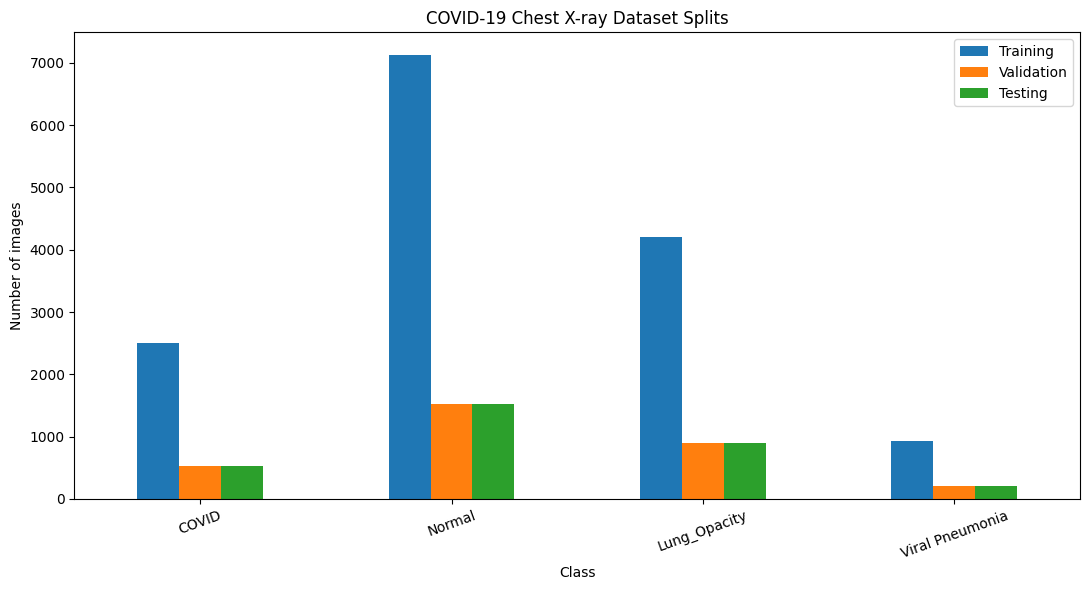

In [20]:
import matplotlib.pyplot as plt

plot_df = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).reindex(CLASS_NAMES, fill_value=0)

plot_df.plot(kind="bar", figsize=(11, 6))

plt.title("COVID-19 Chest X-ray Dataset Splits")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Phase 3

In [21]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("OpenCV version:", cv2.__version__)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

OpenCV version: 4.14.0
TensorFlow version: 2.21.0
NumPy version: 2.1.3


In [22]:
# Image dimensions required by MobileNetV2
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_CHANNELS = 3

# Fixed random seed for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Project directories
PROJECT_DIR = Path("/content/covid19_project")
SPLIT_DIR = PROJECT_DIR / "splits"

print("Image dimensions:", (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
print("Project directory exists:", PROJECT_DIR.exists())
print("Split directory exists:", SPLIT_DIR.exists())

Image dimensions: (224, 224, 3)
Project directory exists: True
Split directory exists: True


In [23]:
from collections import Counter

dimension_counts = Counter()
failed_reads = 0

for class_name, paths in image_paths_by_class.items():
    for image_path in paths:
        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

        if image is None:
            failed_reads += 1
            continue

        height, width = image.shape
        dimension_counts[(width, height)] += 1

print("Most common image dimensions:\n")

for dimensions, count in dimension_counts.most_common(10):
    print(f"{dimensions[0]} × {dimensions[1]}: {count:,} images")

print("\nDistinct image dimensions:", len(dimension_counts))
print("Images that failed to load:", failed_reads)

Most common image dimensions:

299 × 299: 21,165 images

Distinct image dimensions: 1
Images that failed to load: 0


Image path: /root/.cache/kagglehub/datasets/tawsifurrahman/covid19-radiography-database/versions/5/COVID-19_Radiography_Dataset/COVID/images/COVID-461.png
Original shape: (299, 299)
Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


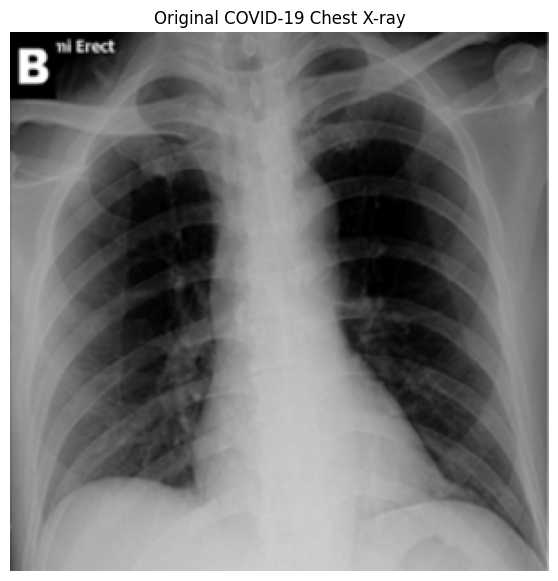

In [24]:
import random

sample_paths = image_paths_by_class["COVID"]

sample_path = random.choice(sample_paths)

original_image = cv2.imread(
    str(sample_path),
    cv2.IMREAD_GRAYSCALE
)

if original_image is None:
    raise ValueError(f"Could not read image: {sample_path}")

print("Image path:", sample_path)
print("Original shape:", original_image.shape)
print("Minimum pixel value:", original_image.min())
print("Maximum pixel value:", original_image.max())
print("Data type:", original_image.dtype)

plt.figure(figsize=(7, 7))
plt.imshow(original_image, cmap="gray")
plt.title("Original COVID-19 Chest X-ray")
plt.axis("off")
plt.show()

Original shape: (299, 299)
Resized shape: (224, 224)


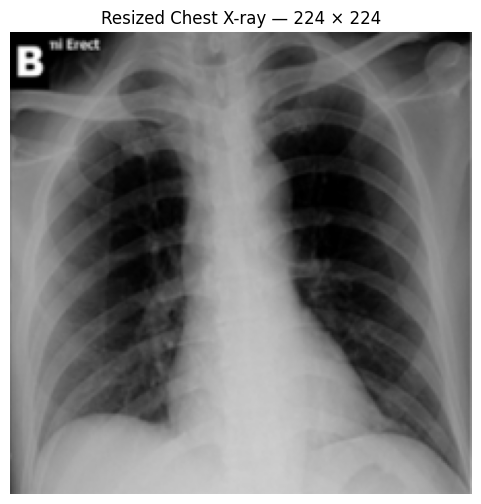

In [25]:
resized_image = cv2.resize(
    original_image,
    (IMG_WIDTH, IMG_HEIGHT),
    interpolation=cv2.INTER_AREA
)

print("Original shape:", original_image.shape)
print("Resized shape:", resized_image.shape)

plt.figure(figsize=(6, 6))
plt.imshow(resized_image, cmap="gray")
plt.title("Resized Chest X-ray — 224 × 224")
plt.axis("off")
plt.show()

In [26]:
rgb_image = cv2.cvtColor(
    resized_image,
    cv2.COLOR_GRAY2RGB
)

print("RGB image shape:", rgb_image.shape)
print("Data type:", rgb_image.dtype)

RGB image shape: (224, 224, 3)
Data type: uint8


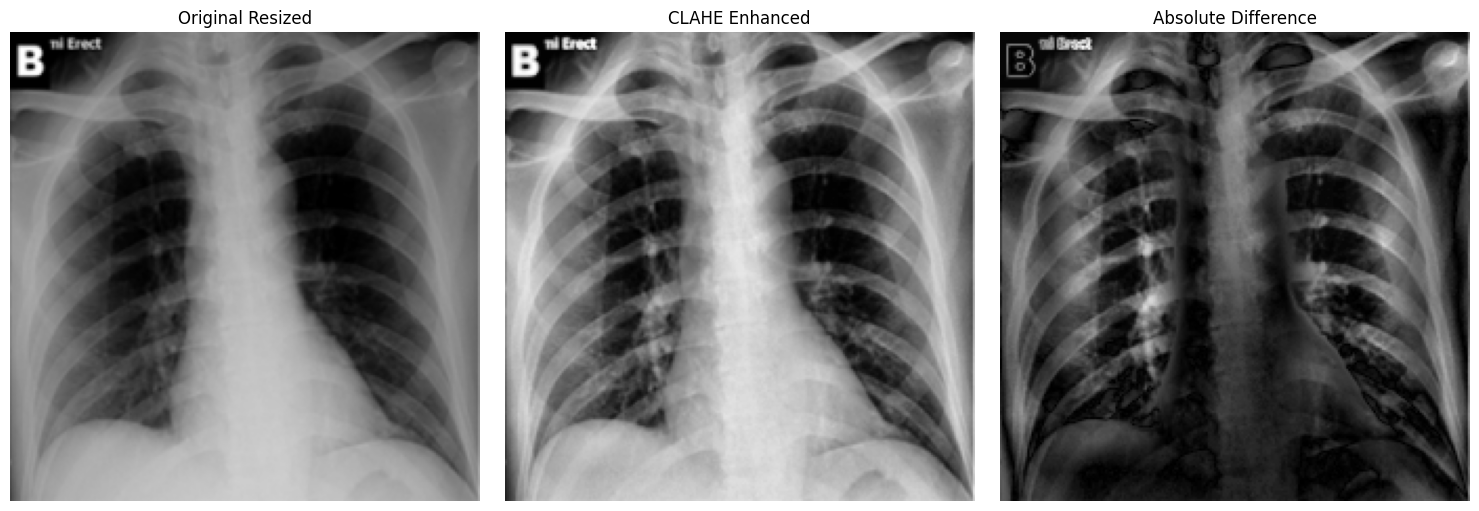

In [27]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(resized_image)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(resized_image, cmap="gray")
plt.title("Original Resized")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE Enhanced")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    cv2.absdiff(resized_image, clahe_image),
    cmap="gray"
)
plt.title("Absolute Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
def preprocess_xray(
    image_path,
    img_size=(224, 224),
    use_clahe=False
):
    """
    Load and preprocess a chest X-ray for MobileNetV2.

    Parameters
    ----------
    image_path : str or Path
        Path to the chest X-ray.
    img_size : tuple
        Target size as (width, height).
    use_clahe : bool
        Whether to apply CLAHE before RGB conversion.

    Returns
    -------
    np.ndarray
        Float32 image with shape (height, width, 3).
        Pixel values are scaled according to MobileNetV2
        preprocessing, normally into the range [-1, 1].
    """

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(f"Unable to read image: {image_path}")

    image = cv2.resize(
        image,
        img_size,
        interpolation=cv2.INTER_AREA
    )

    if use_clahe:
        clahe_operator = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        image = clahe_operator.apply(image)

    # Convert grayscale to three identical channels.
    image = cv2.cvtColor(
        image,
        cv2.COLOR_GRAY2RGB
    )

    # Convert to float32 and apply MobileNetV2 scaling.
    image = image.astype(np.float32)

    image = preprocess_input(image)

    return image

In [29]:
processed_image = preprocess_xray(sample_path)

print("Processed shape:", processed_image.shape)
print("Data type:", processed_image.dtype)
print("Minimum value:", processed_image.min())
print("Maximum value:", processed_image.max())

assert processed_image.shape == (224, 224, 3)
assert processed_image.dtype == np.float32
assert np.isfinite(processed_image).all()

print("\nPreprocessing test passed!")

Processed shape: (224, 224, 3)
Data type: float32
Minimum value: -1.0
Maximum value: 1.0

Preprocessing test passed!


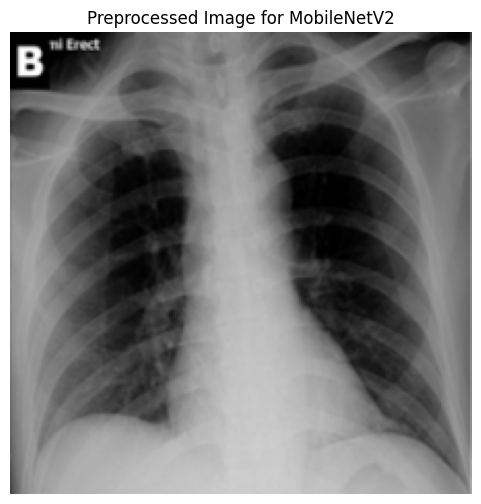

In [30]:
display_image = (processed_image + 1.0) / 2.0
display_image = np.clip(display_image, 0, 1)

plt.figure(figsize=(6, 6))
plt.imshow(display_image)
plt.title("Preprocessed Image for MobileNetV2")
plt.axis("off")
plt.show()

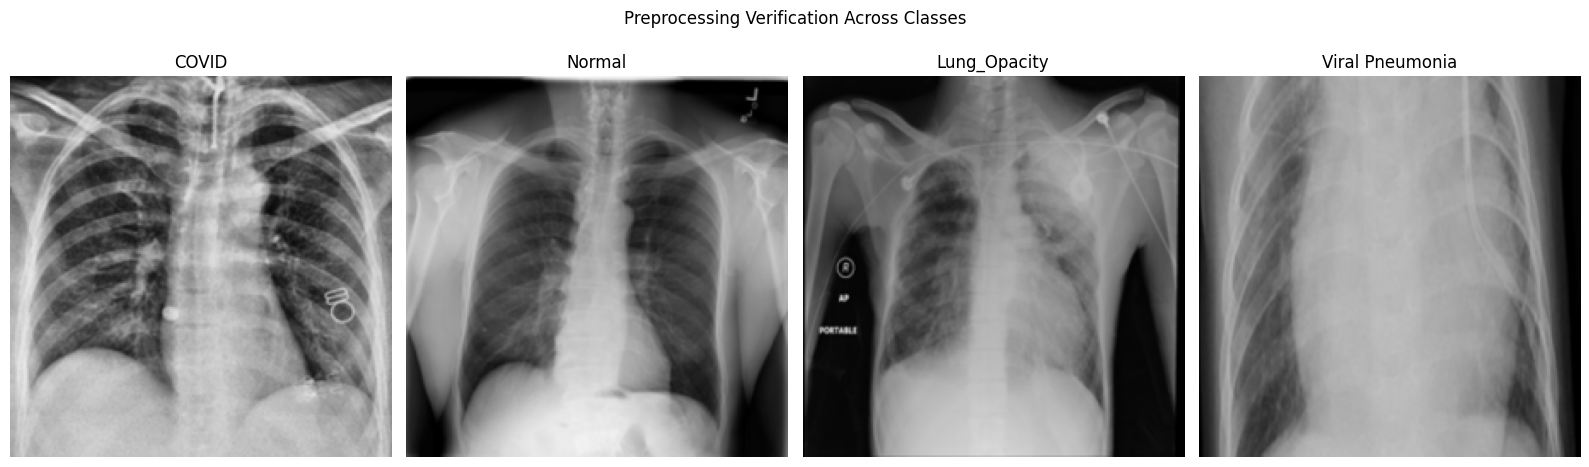

In [31]:
available_classes = [
    name for name in CLASS_NAMES
    if image_paths_by_class.get(name)
]

fig, axes = plt.subplots(
    1,
    len(available_classes),
    figsize=(16, 5)
)

if len(available_classes) == 1:
    axes = [axes]

for ax, class_name in zip(axes, available_classes):

    sample = random.choice(image_paths_by_class[class_name])

    image = preprocess_xray(sample)

    # Convert to display range.
    image = np.clip((image + 1.0) / 2.0, 0, 1)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Preprocessing Verification Across Classes")
plt.tight_layout()
plt.show()

In [32]:
SPLIT_DIR = Path("/content/covid19_project/splits")

for filename in [
    "train.csv",
    "validation.csv",
    "test.csv"
]:
    file_path = SPLIT_DIR / filename

    if file_path.exists():
        print(f"Found: {filename}")
    else:
        print(f"Missing: {filename}")

Found: train.csv
Found: validation.csv
Found: test.csv


In [33]:
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 14777
Validation: 3167
Testing: 3167


## Phase 4

In [45]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

if gpus:
    print("GPU acceleration is available.")
else:
    print("No GPU detected. Training will use the CPU.")

TensorFlow version: 2.21.0
OpenCV version: 4.14.0
Available GPUs: []
No GPU detected. Training will use the CPU.


In [46]:
PROJECT_DIR = Path("/content/covid19_project")
SPLIT_DIR = PROJECT_DIR / "splits"

train_csv = SPLIT_DIR / "train.csv"
val_csv = SPLIT_DIR / "validation.csv"
test_csv = SPLIT_DIR / "test.csv"

for file in [train_csv, val_csv, test_csv]:
    if not file.exists():
        raise FileNotFoundError(
            f"Missing split file: {file}\n"
            "If your Colab runtime restarted, rerun the dataset "
            "download and split-generation steps."
        )

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

print("\nTesting class distribution:")
print(test_df["label"].value_counts())

Training images: 14777
Validation images: 3167
Testing images: 3167

Training class distribution:
label
Normal             7133
Lung_Opacity       4208
COVID              2500
Viral Pneumonia     936
Name: count, dtype: int64

Validation class distribution:
label
Normal             1529
Lung_Opacity        902
COVID               535
Viral Pneumonia     201
Name: count, dtype: int64

Testing class distribution:
label
Normal             1529
Lung_Opacity        902
COVID               535
Viral Pneumonia     201
Name: count, dtype: int64


In [47]:
CLASS_NAMES = [
    "COVID",
    "Normal",
    "Lung_Opacity",
    "Viral Pneumonia"
]

NUM_CLASSES = len(CLASS_NAMES)

class_to_index = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

index_to_class = {
    index: name for name, index in class_to_index.items()
}

print("Class mapping:")
for name, index in class_to_index.items():
    print(f"{name}: {index}")

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    unknown_labels = set(split_df["label"]) - set(CLASS_NAMES)

    if unknown_labels:
        raise ValueError(
            f"Unexpected labels in {split_name}: {unknown_labels}"
        )

    missing_files = [
        p for p in split_df["filepath"]
        if not Path(p).is_file()
    ]

    if missing_files:
        raise FileNotFoundError(
            f"{split_name} has missing image files. "
            f"First missing path: {missing_files[0]}"
        )

print("\nAll labels and image paths are valid.")

Class mapping:
COVID: 0
Normal: 1
Lung_Opacity: 2
Viral Pneumonia: 3

All labels and image paths are valid.


In [48]:
def load_xray_opencv(image_path, label):
    """
    Read and preprocess a chest X-ray using OpenCV.
    """

    # Convert the incoming path to a Python string.
    if isinstance(image_path, np.ndarray):
        image_path = image_path.item()

    if isinstance(image_path, bytes):
        image_path = image_path.decode("utf-8")
    else:
        image_path = str(image_path)

    # Convert label into an integer.
    label = int(np.asarray(label).item())

    # Read image using OpenCV.
    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    # Resize image.
    image = cv2.resize(
        image,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    # Convert grayscale to RGB.
    image = cv2.cvtColor(
        image,
        cv2.COLOR_GRAY2RGB
    )

    # Convert to float32.
    image = image.astype(np.float32)

    # Normalize for MobileNetV2.
    image = preprocess_input(image)

    return image, np.int32(label)

In [55]:
BATCH_SIZE = 32

def load_xray_fast(image_path, label):

    # Read image file
    image_bytes = tf.io.read_file(image_path)

    # Decode PNG/JPEG image into grayscale
    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )

    # Resize to MobileNetV2 input dimensions
    image = tf.image.resize(
        image,
        [224, 224],
        method="bilinear"
    )

    # Convert grayscale to RGB
    image = tf.image.grayscale_to_rgb(image)

    # Normalize to [-1, 1] for MobileNetV2
    image = preprocess_input(image)

    image = tf.ensure_shape(image, [224, 224, 3])

    return image, label


def create_fast_dataset(dataframe, training=False):

    filepaths = dataframe["filepath"].astype(str).values

    labels = (
        dataframe["label"]
        .map(class_to_index)
        .astype(np.int32)
        .values
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=3000,
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_xray_fast,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [51]:
train_labels = (
    train_df["label"]
    .map(class_to_index)
    .astype(np.int32)
    .values
)

class_ids = np.arange(NUM_CLASSES)

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=train_labels
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_ids, weights)
}

print("Class weights:")

for class_id, weight in class_weights.items():
    print(f"{index_to_class[class_id]}: {weight:.4f}")

Class weights:
COVID: 1.4777
Normal: 0.5179
Lung_Opacity: 0.8779
Viral Pneumonia: 3.9468


In [52]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Freeze the pretrained feature extractor for initial training.
base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="xray_image"
)

# Keep the pretrained model in inference mode.
x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_predictions"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="COVID19_Xray_MobileNetV2"
)

model.summary()

Model: "COVID19_Xray_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_predictions (Dense)       │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [53]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [56]:
train_ds = create_fast_dataset(train_df, training=True)
val_ds = create_fast_dataset(val_df)
test_ds = create_fast_dataset(test_df)

print("Optimized datasets ready!")

Optimized datasets ready!


In [57]:
EPOCHS = 8

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/8
462/462 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8029 - loss: 0.4193
Epoch 1: val_loss improved from None to 0.45136, saving model to /content/covid19_project/models/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/covid19_project/models/mobilenetv2_best.keras
462/462 ━━━━━━━━━━━━━━━━━━━━ 748s 2s/step - accuracy: 0.8119 - loss: 0.4043 - val_accuracy: 0.8248 - val_loss: 0.4514 - learning_rate: 0.0010
Epoch 2/8
462/462 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8230 - loss: 0.3671
Epoch 2: val_loss improved from 0.45136 to 0.41117, saving model to /content/covid19_project/models/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/covid19_project/models/mobilenetv2_best.keras
462/462 ━━━━━━━━━━━━━━━━━━━━ 740s 2s/step - accuracy: 0.8229 - loss: 0.3667 - val_accuracy: 0.8396 - val_loss: 0.4112 - learning_rate: 0.0010
Epoch 3/8
462/462 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8376 - loss: 0.3532
Epoch 3: val_loss improved from 0.41117 t

## Phase 5

In [59]:
from pathlib import Path
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if Path(BEST_MODEL_PATH).exists():
    model = tf.keras.models.load_model(BEST_MODEL_PATH)
    print("Best checkpoint loaded successfully.")
else:
    print("Checkpoint not found. Using the model currently in memory.")

Best checkpoint loaded successfully.


In [60]:
test_results = model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\nTEST SET RESULTS")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

99/99 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.8696 - loss: 0.3530

TEST SET RESULTS
accuracy: 0.8696
loss: 0.3530


In [61]:
# Generate probabilities for all test images
y_prob = model.predict(
    test_ds,
    verbose=1
)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Get the actual labels from the test dataframe
y_true = (
    test_df["label"]
    .map(class_to_index)
    .to_numpy(dtype=np.int32)
)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)
print("Probability matrix:", y_prob.shape)

assert len(y_true) == len(y_pred), "Prediction count mismatch!"
assert y_prob.shape[1] == NUM_CLASSES

99/99 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step
Actual labels: (3167,)
Predicted labels: (3167,)
Probability matrix: (3167, 4)


In [62]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print(report)

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          COVID     0.8757    0.8561    0.8658       535
         Normal     0.9133    0.8542    0.8827      1529
   Lung_Opacity     0.7970    0.8836    0.8381       902
Viral Pneumonia     0.9019    0.9602    0.9301       201

       accuracy                         0.8696      3167
      macro avg     0.8720    0.8885    0.8792      3167
   weighted avg     0.8731    0.8696    0.8702      3167



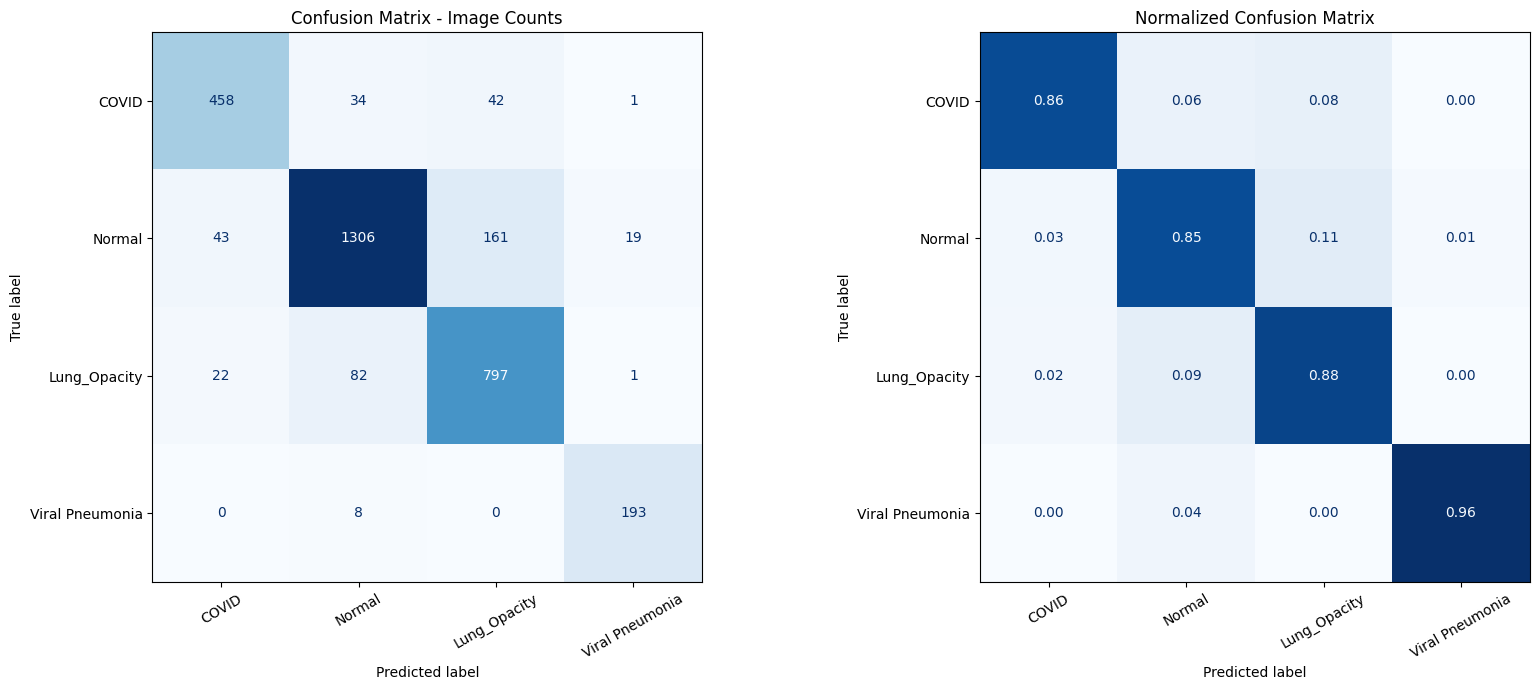

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# 1. Calculate the ordinary confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

# 2. Calculate normalized confusion matrix separately
cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    normalize="true"
)

# 3. Create two plots
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Original confusion matrix
disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp1.plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("Confusion Matrix - Image Counts")
axes[0].tick_params(axis="x", rotation=30)

# Normalized confusion matrix
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=CLASS_NAMES
)

disp2.plot(
    ax=axes[1],
    cmap="Blues",
    values_format=".2f",
    colorbar=False
)

axes[1].set_title("Normalized Confusion Matrix")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [65]:
from sklearn.metrics import confusion_matrix

print("CLASS-WISE PERFORMANCE\n")

for i, class_name in enumerate(CLASS_NAMES):

    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - (tp + fn + fp)

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0

    print(f"{class_name}")
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print("-" * 35)

CLASS-WISE PERFORMANCE

COVID
Sensitivity: 0.8561
Specificity: 0.9753
-----------------------------------
Normal
Sensitivity: 0.8542
Specificity: 0.9243
-----------------------------------
Lung_Opacity
Sensitivity: 0.8836
Specificity: 0.9104
-----------------------------------
Viral Pneumonia
Sensitivity: 0.9602
Specificity: 0.9929
-----------------------------------


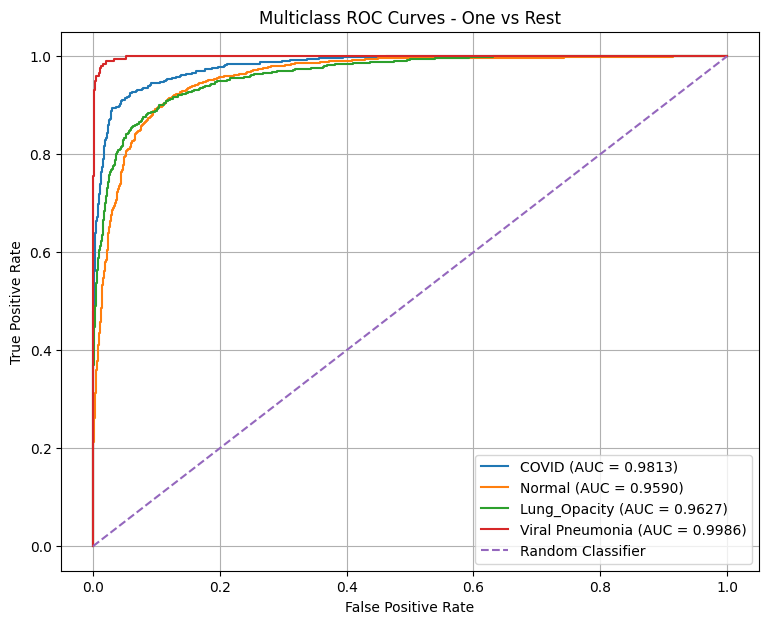

Macro AUC: 0.9754
Weighted AUC: 0.9663


In [66]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

y_true_binary = label_binarize(
    y_true,
    classes=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(9, 7))

for i, class_name in enumerate(CLASS_NAMES):

    fpr, tpr, thresholds = roc_curve(
        y_true_binary[:, i],
        y_prob[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves - One vs Rest")
plt.legend()
plt.grid(True)
plt.show()

macro_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

print("Macro AUC:", round(macro_auc, 4))
print("Weighted AUC:", round(weighted_auc, 4))

Total incorrect predictions: 413
Total test images: 3167


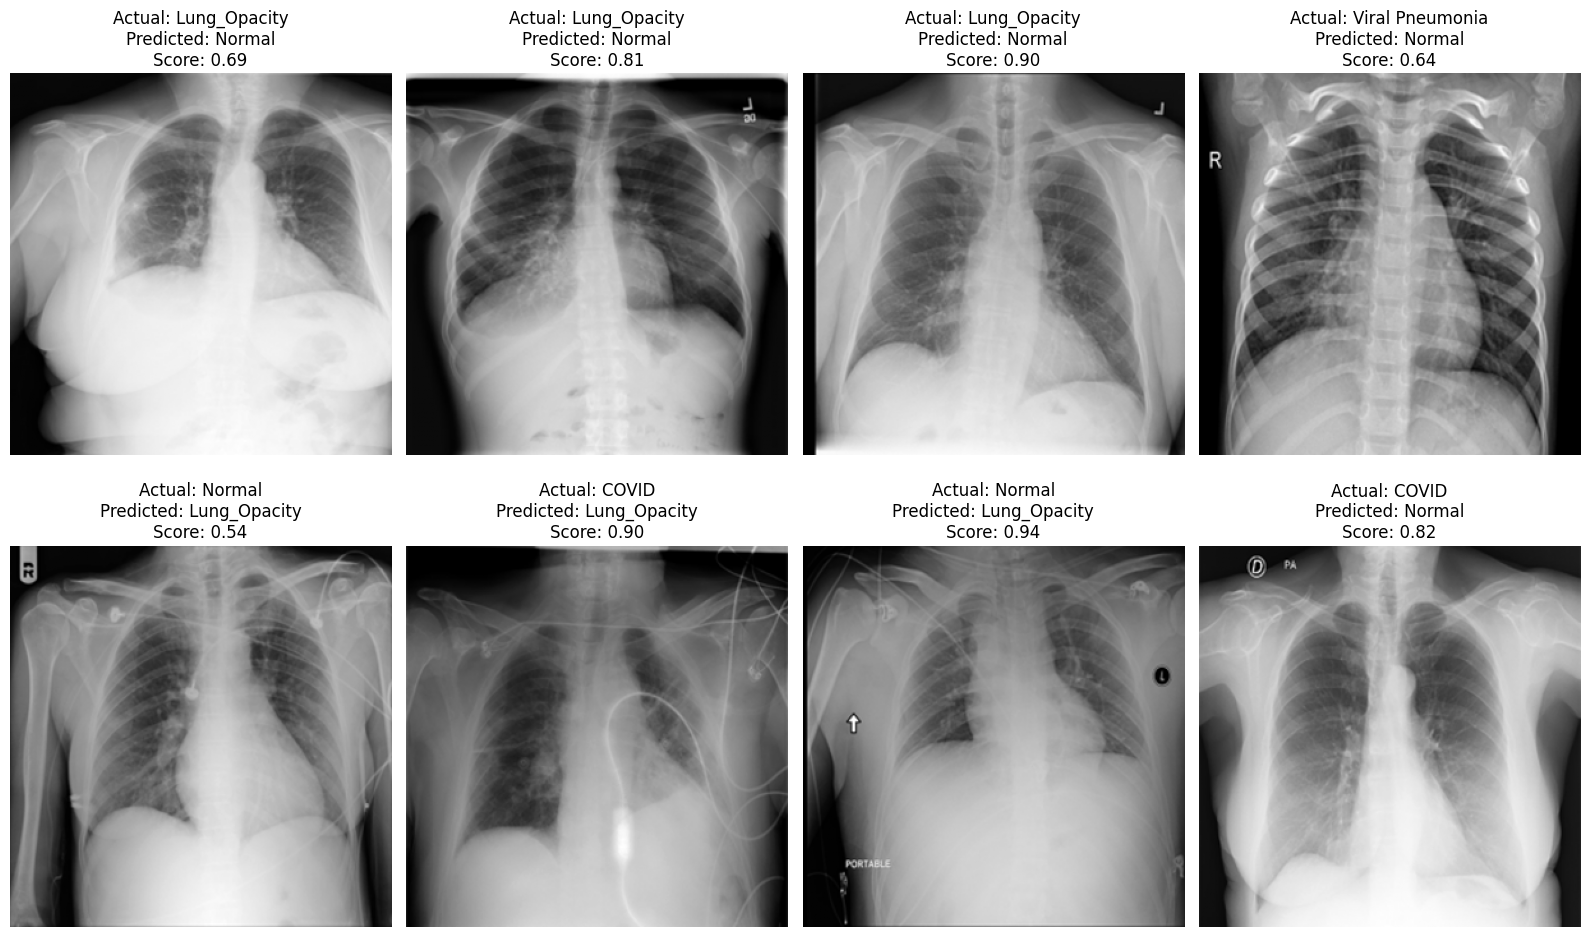

In [67]:
wrong_indices = np.where(y_true != y_pred)[0]

print("Total incorrect predictions:", len(wrong_indices))
print("Total test images:", len(y_true))

# Show up to 8 incorrect predictions
num_examples = min(8, len(wrong_indices))

plt.figure(figsize=(16, 10))

for plot_index, test_index in enumerate(
    wrong_indices[:num_examples]
):

    image_path = test_df.iloc[test_index]["filepath"]

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    actual_class = index_to_class[int(y_true[test_index])]
    predicted_class = index_to_class[int(y_pred[test_index])]

    probability = float(y_prob[test_index][y_pred[test_index]])

    plt.subplot(2, 4, plot_index + 1)
    plt.imshow(image, cmap="gray")

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Score: {probability:.2f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [68]:
RESULTS_DIR = PROJECT_DIR / "evaluation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save individual predictions
predictions_df = pd.DataFrame({
    "filepath": test_df["filepath"].values,
    "actual_label": [
        index_to_class[int(i)] for i in y_true
    ],
    "predicted_label": [
        index_to_class[int(i)] for i in y_pred
    ],
    "predicted_score": np.max(y_prob, axis=1)
})

# Save each class probability
for i, class_name in enumerate(CLASS_NAMES):
    predictions_df[f"score_{class_name}"] = y_prob[:, i]

predictions_df.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

# Save classification report
report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

# Save summary metrics
summary = {
    "test_loss": test_results.get("loss"),
    "test_accuracy": test_results.get("accuracy"),
    "macro_auc_ovr": macro_auc,
    "weighted_auc_ovr": weighted_auc
}

pd.DataFrame([summary]).to_csv(
    RESULTS_DIR / "evaluation_summary.csv",
    index=False
)

print("Evaluation results saved in:", RESULTS_DIR)

Evaluation results saved in: /content/covid19_project/evaluation
